In [2]:
import json
import math
import matplotlib.pyplot as plt


def plotSolution(data,solution):

    # Charger le GeoJSON
    with open("countries.geo.json") as f:
        dataCountries = json.load(f)

    # get some data
    minVisiDuration = data['minVisiDuration']
    AOIs = data['AOIs']
    accesses = data['Accesses']
    satPasses = data['Passes']
    
    # get the booking strategy
    bookings = solution['Bookings']
    bookings.sort(key=lambda item: satPasses[item["passId"]]['startDate'])    
    print("Bookings:")
    for booking in bookings:
        print(booking)
    
    # show the passes used
    ncols = 3
    nrows = math.ceil(len(solution['Bookings']) / ncols)
    fig, axs = plt.subplots(nrows=nrows,ncols=ncols, figsize=(30,30))
    axs = axs.flatten()

    i = 0
    for booking in solution['Bookings']:
        passId = booking["passId"]
        satPass = satPasses[passId]
        ax = axs[i]
        
        # Dessiner les frontières
        for feature in dataCountries["features"]:
            geometry = feature["geometry"]
    
            if geometry["type"] == "Polygon":
                for coords in geometry["coordinates"]:
                    xs, ys = zip(*coords)
                    ax.fill(xs, ys, facecolor="lightgray", edgecolor="black", linewidth=0.5)

            elif geometry["type"] == "MultiPolygon":
                for polygon in geometry["coordinates"]:
                    for coords in polygon:
                        xs, ys = zip(*coords)
                        ax.fill(xs, ys, facecolor="lightgray", edgecolor="black", linewidth=0.5)

        
        ax.set_xlim(-9, 13)
        ax.set_ylim(38, 56)
        ax.set_title("Pass #{} [{},{}]".format(passId,satPass['startDate'],satPass['endDate']))
        ax.plot([aoi['lon'] for aoi in AOIs], [aoi['lat'] for aoi in AOIs], 'kx')

        # show the reservations
        xpoints = []
        ypoints = []
        colors = []
        for accessId in satPass['accessIds']:
            access = accesses[accessId]
            aoi = AOIs[access['aoiId']]
            xpoints.append(aoi['lon'])
            ypoints.append(aoi['lat'])
            if (booking['bookingStart'] <= access['end'] - minVisiDuration) and (access['start'] + minVisiDuration <= booking['bookingEnd']):
                colors.append('r')
            else:
                colors.append('b')       
        ax.scatter(xpoints,ypoints,marker='o',c=colors)
        
        i = i + 1


plt.show()

In [3]:
# import the data

dataFile = open('../data/data12.json')  
data = json.load(dataFile)
accesses = data['Accesses']
obsRequests = data['ObservationRequests'];
nObsRequests = len(obsRequests)
satPasses = data['Passes'];



Modele avec passage partiels 

In [ ]:
%pip install gurobipy
import gurobipy as gp
from gurobipy import GRB


passes = data['Passes']
accesses = data['Accesses']
requests = data['ObservationRequests']
D = data['minVisiDuration']          # 30 s
Npassages = len(passes)
Nacces = len(accesses)
m = gp.Model("passages_partiels")

# Variables
x     = m.addVars(Npassages,   vtype=GRB.BINARY,  name="x")      # passage réservé
debut = m.addVars(Npassages,   vtype=GRB.INTEGER, name="debut")  # début de notre réservation
fin   = m.addVars(Npassages,   vtype=GRB.INTEGER, name="fin")    # fin de notre réservation
z     = m.addVars(Nacces, vtype=GRB.BINARY,  name="z")      # accès observé

# Contraintes sur chaque passage 
for i, p in enumerate(passes):
    # la réservation reste à l'intérieur du passage
    debut[i].LB = fin[i].LB = p['start']
    debut[i].UB = fin[i].UB = p['end']
    m.addConstr(debut[i] <= fin[i])
    # si le passage n'est pas réservé, la durée réservée est nulle
    m.addConstr(fin[i] - debut[i] <= (p['end'] - p['start'])  * x[i])

# Contraintes sur chaque accès 
for a, acc in enumerate(accesses):
    if acc['end'] - acc['start'] < D:        # accès trop court : jamais observable
        z[a].UB = 0
        continue
    p_id = acc['passId']
    p = passes[p_id]
    M = (p['end'] - p['start']) + D          # la constante "big-M"

    m.addConstr(z[a] <= x[p_id])                                        # lien avec le passage
    m.addConstr(debut[p_id] <= acc['end'] - D + M * (1 - z[a]))         # commence assez tôt
    m.addConstr(fin[p_id] >= acc['start'] + D - M * (1 - z[a]))       # finit assez tard
    m.addConstr(fin[p_id] - debut[p_id] >= D * z[a])                    # fenêtre d'au moins D secondes
    # (sans cette dernière contrainte, une fenêtre de 10 s au milieu d'un accès
    #  serait comptée comme une observation : le chevauchement doit faire >= D)

#  Contraintes sur chaque requête : au moins un accès observé 
for req in requests:
    m.addConstr(gp.quicksum(z[a] for a in req['accessIds']) >= 1)

#  Objectif 
cout = gp.quicksum(
    data['fixedPassCost'] * x[i] + data['passCostPerTimeUnit'] * (fin[i] - debut[i])
    for i in range(Npassages)
)
m.setObjective(cout, GRB.MINIMIZE)

m.setParam('TimeLimit', 120)
m.optimize()

# --- Résultat ---
selectedPassIds = [i for i in range(len(passes)) if x[i].X > 0.5]
for i in selectedPassIds:
    print(f"Passage {i} : de {debut[i].X:.0f} à {fin[i].X:.0f}")
print("Coût total :", m.ObjVal)

# export the solution to json (fenêtres partielles trouvées par le modèle)
bookings = []
for i in selectedPassIds:
    satPass = satPasses[i]
    bookings.append({"passId": i, "passStart": satPass['start'], "passEnd": satPass['end'],
                     "bookingStart": int(round(debut[i].X)), "bookingEnd": int(round(fin[i].X))})
with open("mySolution.json", "w") as jsonFile:
    json.dump({"Bookings": bookings}, jsonFile)

Bookings:
{'passId': 6, 'passStart': 3748, 'passEnd': 3945, 'bookingStart': 3808, 'bookingEnd': 3885}
{'passId': 31, 'passStart': 20690, 'passEnd': 20920, 'bookingStart': 20750, 'bookingEnd': 20860}
{'passId': 34, 'passStart': 23170, 'passEnd': 23507, 'bookingStart': 23230, 'bookingEnd': 23447}
{'passId': 67, 'passStart': 42288, 'passEnd': 42569, 'bookingStart': 42348, 'bookingEnd': 42509}


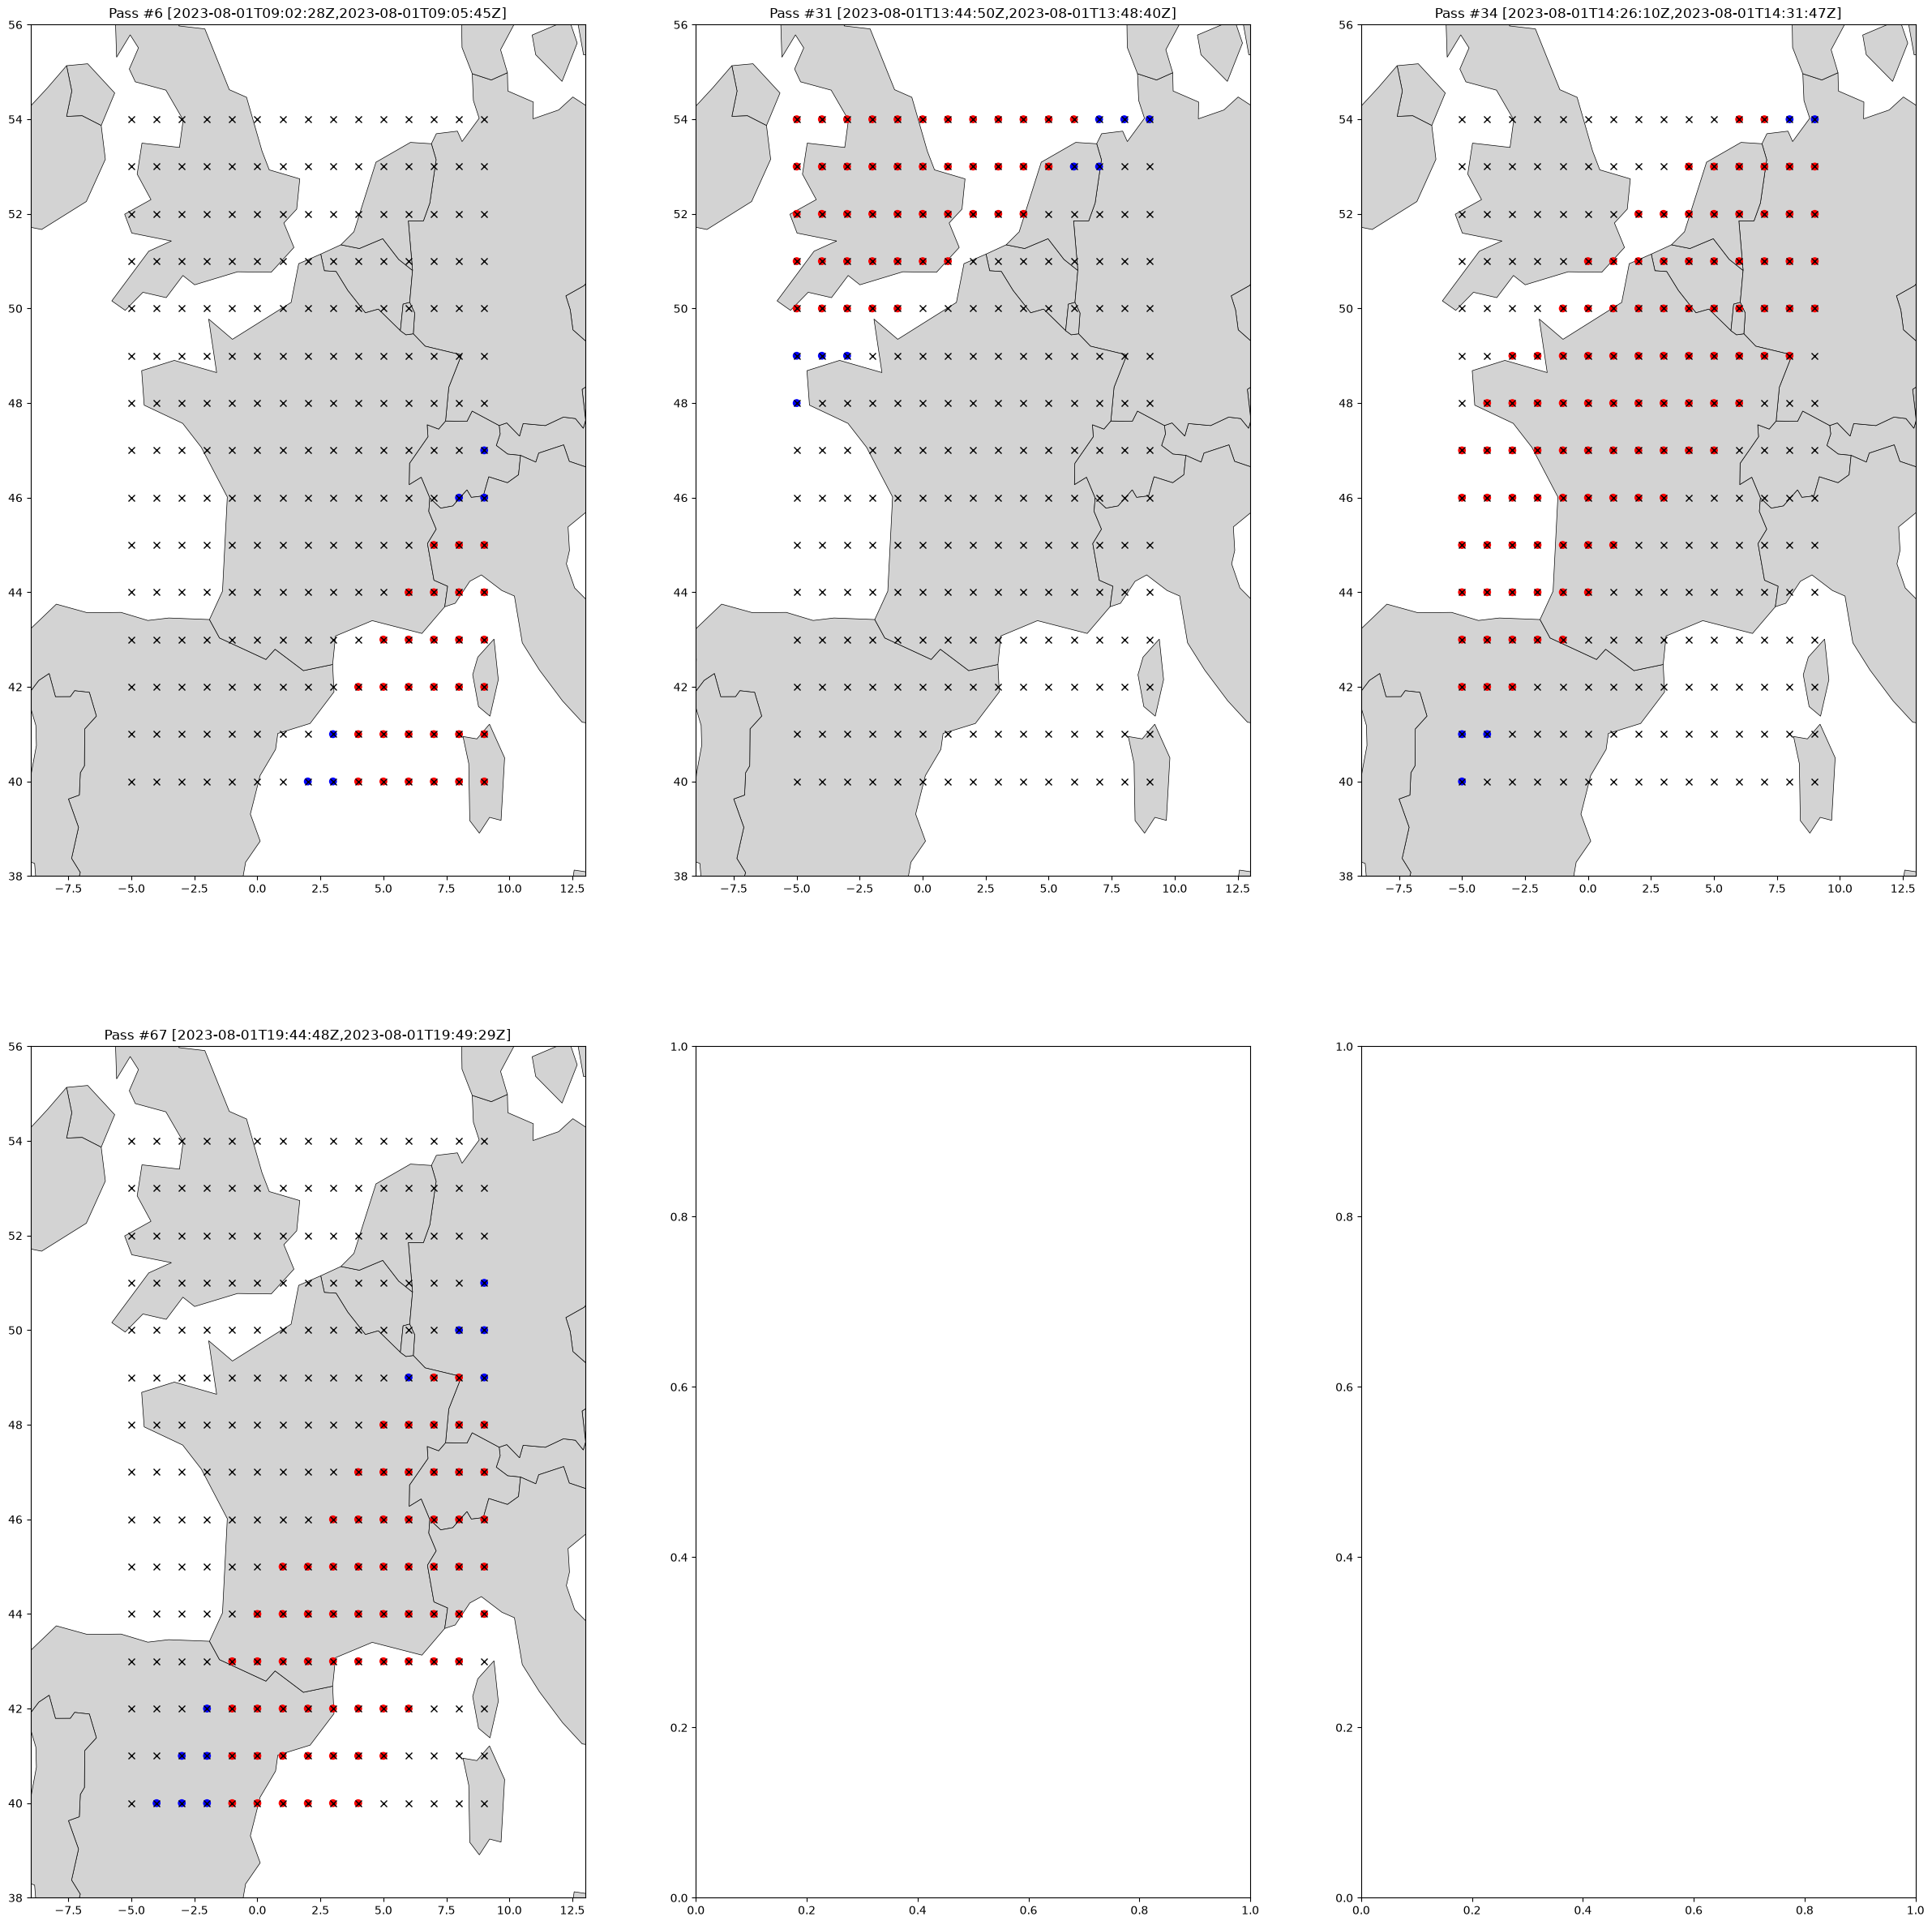

In [5]:
# import the solution
solutionFile = open('mySolution.json')  
solution = json.load(solutionFile)
plotSolution(data,solution)